In [1]:
# Cell 1 — Imports and model configuration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    DT, SIM_TIME,
    VEHICLE_LENGTH, MIN_GAP,
    DESIRED_GAP,
    HDV_ACCEL_MIN, HDV_ACCEL_MAX, HDV_SPEED_MAX,
    AV_ACCEL_MIN, AV_ACCEL_MAX, AV_SPEED_MAX,
    AV_DESIRED_SPEED,
    MPC_HORIZON,
    AV_HEADWAY_TARGET,
    PEDESTRIAN_TIME, PEDESTRIAN_POSITION,
    PEDESTRIAN_DURATION, PEDESTRIAN_WARNING_DURATION,
    PEDESTRIAN_HDV_SAFE_DISTANCE,
    PEDESTRIAN_HDV_COMFORT_BRAKE,
)

from src.dynamics import calculate_gap, HDVDynamics

from src.simulation import simulate

from src.pedestrian import (
    X_STOP,
    MODE_FREE,
    MODE_STOPPING,
    MODE_COMMITTED,
)

MODE_NAMES = {
    MODE_FREE: "FREE",
    MODE_STOPPING: "STOPPING",
    MODE_COMMITTED: "COMMITTED",
}

T_WARNING_START = PEDESTRIAN_TIME - PEDESTRIAN_WARNING_DURATION
T_PEDESTRIAN_END = PEDESTRIAN_TIME + PEDESTRIAN_DURATION

FIG_WIDTH = 12

print(f"DT = {DT} s")
print(f"Simulation time = {SIM_TIME} s")
print(f"Vehicle length = {VEHICLE_LENGTH} m")
print(f"Minimum gap = {MIN_GAP} m")
print(f"Desired HDV gap = {DESIRED_GAP} m")

print()
print(f"Pedestrian warning: {T_WARNING_START:.1f}–{PEDESTRIAN_TIME:.1f} s")
print(f"Pedestrian active:  {PEDESTRIAN_TIME:.1f}–{T_PEDESTRIAN_END:.1f} s")
print(f"Pedestrian position: {PEDESTRIAN_POSITION:.1f} m")
print(f"HDV stop target: {X_STOP:.1f} m")

print()
print(f"AV desired speed: {AV_DESIRED_SPEED:.1f} m/s")
print(f"AV acceleration limits: {AV_ACCEL_MIN:.1f} to {AV_ACCEL_MAX:.1f} m/s²")
print(f"AV MPC horizon: {MPC_HORIZON} steps ({MPC_HORIZON * DT:.1f} s)")
print(f"AV target headway: {AV_HEADWAY_TARGET:.1f} s")

DT = 1 s
Simulation time = 60.0 s
Vehicle length = 4.5 m
Minimum gap = 2.0 m
Desired HDV gap = 10.0 m

Pedestrian warning: 17.0–20.0 s
Pedestrian active:  20.0–30.0 s
Pedestrian position: 400.0 m
HDV stop target: 395.0 m

AV desired speed: 20.0 m/s
AV acceleration limits: -8.0 to 3.0 m/s²
AV MPC horizon: 3 steps (3.0 s)
AV target headway: 1.5 s


In [2]:
# Cell 2 — Load the mixed-traffic initial conditions

from src.dataloader import load_data

df = load_data()

print("Initial mixed-traffic configuration:")
display(df)

print(f"Number of vehicles: {len(df)}")

print("\nVehicle types:")
print(df["type"].value_counts())

print("\nVehicle order:")
display(
    df[["vehicle_id", "position_m", "speed_mps", "type"]]
)

Initial mixed-traffic configuration:


,vehicle_id,position_m,speed_mps,type
0,0,199.50,13.83,HDV
1,1,187.52,15.04,HDV
2,2,172.36,17.25,HDV
3,3,157.54,16.32,HDV
4,4,141.48,14.91,HDV
5,5,127.20,18.12,HDV
6,6,112.52,13.39,HDV
7,7,101.46,14.92,AV
8,8,86.12,15.66,HDV
9,9,72.26,16.56,HDV


Number of vehicles: 15

Vehicle types:
type
HDV    11
AV      4
Name: count, dtype: int64

Vehicle order:


,vehicle_id,position_m,speed_mps,type
0,0,199.50,13.83,HDV
1,1,187.52,15.04,HDV
2,2,172.36,17.25,HDV
3,3,157.54,16.32,HDV
4,4,141.48,14.91,HDV
5,5,127.20,18.12,HDV
6,6,112.52,13.39,HDV
7,7,101.46,14.92,AV
8,8,86.12,15.66,HDV
9,9,72.26,16.56,HDV


In [3]:
# Cell 3 — Initial gaps and vehicle control type

df["gap_m"] = np.nan
df["initial_accel_mps2"] = np.nan
df["control_type"] = ""

for i in range(len(df)):

    if i == 0:
        df.loc[i, "control_type"] = "HDV leader"
        continue

    # Gap to the vehicle directly ahead
    df.loc[i, "gap_m"] = calculate_gap(
        df.loc[i - 1, "position_m"],
        df.loc[i, "position_m"]
    )

    if df.loc[i, "type"] == "HDV":

        # HDV uses the car-following model
        df.loc[i, "initial_accel_mps2"] = (
            HDVDynamics.calculate_acceleration(
                df.loc[i, "speed_mps"],
                df.loc[i - 1, "speed_mps"],
                df.loc[i, "gap_m"]
            )
        )

        df.loc[i, "control_type"] = "HDV car-following"

    elif df.loc[i, "type"] == "AV":

        # AV acceleration is determined by MPC during simulation.
        df.loc[i, "control_type"] = "AV MPC"

display(
    df[
        [
            "vehicle_id",
            "type",
            "position_m",
            "speed_mps",
            "gap_m",
            "control_type",
            "initial_accel_mps2",
        ]
    ]
)

print("\nInitial vehicle counts:")
print(df["type"].value_counts())

print("\nAV vehicle IDs:")
print(df.loc[df["type"] == "AV", "vehicle_id"].tolist())

print("\nHDV vehicle IDs:")
print(df.loc[df["type"] == "HDV", "vehicle_id"].tolist())

,vehicle_id,type,position_m,speed_mps,gap_m,control_type,initial_accel_mps2
0,0,HDV,199.50,13.83,NaN,HDV leader,NaN
1,1,HDV,187.52,15.04,7.48,HDV car-following,-1.109
2,2,HDV,172.36,17.25,10.66,HDV car-following,-0.973
3,3,HDV,157.54,16.32,10.32,HDV car-following,0.529
4,4,HDV,141.48,14.91,11.56,HDV car-following,1.017
5,5,HDV,127.20,18.12,9.78,HDV car-following,-1.649
6,6,HDV,112.52,13.39,10.18,HDV car-following,2.401
7,7,AV,101.46,14.92,6.56,AV MPC,NaN
8,8,HDV,86.12,15.66,10.84,HDV car-following,-0.202
9,9,HDV,72.26,16.56,9.36,HDV car-following,-0.578



Initial vehicle counts:
type
HDV    11
AV      4
Name: count, dtype: int64

AV vehicle IDs:
[7, 10, 12, 14]

HDV vehicle IDs:
[0, 1, 2, 3, 4, 5, 6, 8, 9, 11, 13]


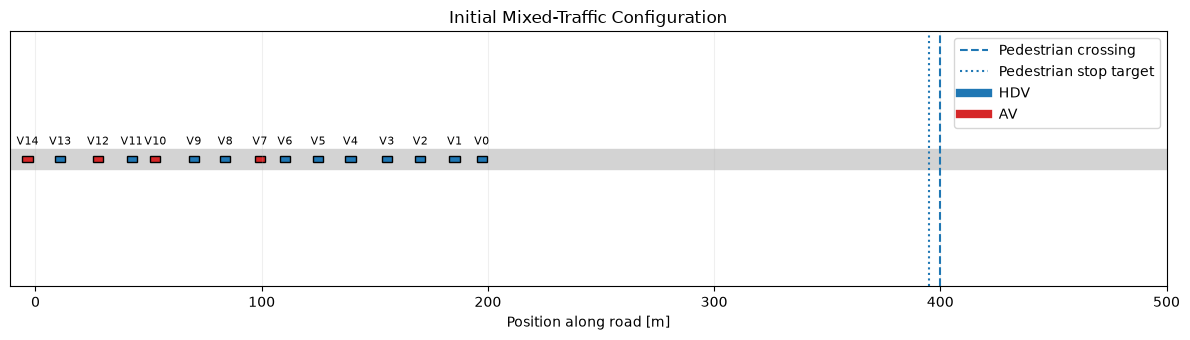

In [4]:
# Cell 4 — Initial mixed-traffic scene

VEHICLE_HEIGHT = 0.09
ROAD_Y = 0.0
ROAD_HEIGHT = 0.2 + VEHICLE_HEIGHT

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.5))

road_left = df["position_m"].min() - 10
road_right = max(500, PEDESTRIAN_POSITION + 50)

ax.add_patch(
    plt.Rectangle(
        (road_left, -ROAD_HEIGHT / 2),
        road_right - road_left,
        ROAD_HEIGHT,
        facecolor="lightgray",
        edgecolor="lightgray",
        linewidth=1.0
    )
)

for _, row in df.iterrows():

    x = row["position_m"]

    if row["type"] == "AV":
        facecolor = "tab:red"
    else:
        facecolor = "tab:blue"

    ax.add_patch(
        plt.Rectangle(
            (x - VEHICLE_LENGTH, ROAD_Y - VEHICLE_HEIGHT / 2),
            VEHICLE_LENGTH,
            VEHICLE_HEIGHT,
            facecolor=facecolor,
            edgecolor="black",
            linewidth=1.0
        )
    )

    ax.text(
        x - VEHICLE_LENGTH / 2,
        VEHICLE_HEIGHT / 2 + 0.12,
        f"V{int(row['vehicle_id'])}",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Pedestrian crossing
ax.axvline(
    PEDESTRIAN_POSITION,
    linestyle="--",
    linewidth=1.5,
    label="Pedestrian crossing"
)

# HDV/queue stopping position
ax.axvline(
    X_STOP,
    linestyle=":",
    linewidth=1.5,
    label="Pedestrian stop target"
)

# Legend handles for vehicle types
ax.plot([], [], color="tab:blue", linewidth=6, label="HDV")
ax.plot([], [], color="tab:red", linewidth=6, label="AV")

ax.set_xlim(road_left, road_right)
ax.set_ylim(-1.8, 1.8)
ax.set_xlabel("Position along road [m]")
ax.set_yticks([])
ax.set_title("Initial Mixed-Traffic Configuration")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

In [5]:
# Cell 5 — Run the mixed-traffic simulation

results = simulate(df)

time = results["time"]
positions = results["positions"]
speeds = results["speeds"]
accelerations = results["accelerations"]
gaps = results["gaps"]

vehicle_types = results["vehicle_types"]

pedestrian_state = results["pedestrian_state"]
pedestrian_accelerations = results["pedestrian_accelerations"]

modes = results["modes"]
wall_hits = results["wall_hits"]
infeasible_events = results["infeasible_events"]

mpc_diagnostics = results["mpc_diagnostics"]

print(f"Simulation duration: {time[-1]:.1f} s")
print(f"Number of vehicles: {positions.shape[1]}")
print(f"Number of time steps: {len(time)}")

print()
print("Mixed-traffic scenario:")
print(f"  HDVs: {np.sum(vehicle_types == 'HDV')}")
print(f"  AVs : {np.sum(vehicle_types == 'AV')}")

print()
print("Vehicle types:")
for i, vehicle_type in enumerate(vehicle_types):
    print(
        f"  Vehicle {int(df.iloc[i]['vehicle_id'])}: "
        f"{vehicle_type}"
    )

Simulation duration: 60.0 s
Number of vehicles: 15
Number of time steps: 61

Mixed-traffic scenario:
  HDVs: 11
  AVs : 4

Vehicle types:
  Vehicle 0: HDV
  Vehicle 1: HDV
  Vehicle 2: HDV
  Vehicle 3: HDV
  Vehicle 4: HDV
  Vehicle 5: HDV
  Vehicle 6: HDV
  Vehicle 7: AV
  Vehicle 8: HDV
  Vehicle 9: HDV
  Vehicle 10: AV
  Vehicle 11: HDV
  Vehicle 12: AV
  Vehicle 13: HDV
  Vehicle 14: AV


In [6]:
# Cell 6 — Basic simulation summary

print("===== MIXED-TRAFFIC SIMULATION SUMMARY =====")

print(f"Final simulation time: {time[-1]:.1f} s")
print(f"Vehicles: {positions.shape[1]}")

print(f"HDVs: {np.sum(vehicle_types == 'HDV')}")
print(f"AVs : {np.sum(vehicle_types == 'AV')}")

print(f"Minimum simulated gap: {np.nanmin(gaps):.2f} m")
print(f"Maximum simulated speed: {np.max(speeds):.2f} m/s")
print(f"Minimum simulated speed: {np.min(speeds):.2f} m/s")

print(f"HDV pedestrian-wall hits: {int(np.sum(wall_hits))}")
print(f"HDV infeasible events: {len(infeasible_events)}")

# Count MPC solves
total_mpc_solves = 0
successful_mpc_solves = 0
failed_mpc_solves = 0

for row in mpc_diagnostics:
    for diagnostics in row:
        if diagnostics is not None:
            total_mpc_solves += 1

            if diagnostics["success"]:
                successful_mpc_solves += 1
            else:
                failed_mpc_solves += 1

print()
print("===== AV MPC SUMMARY =====")
print(f"Total MPC solves: {total_mpc_solves}")
print(f"Successful solves: {successful_mpc_solves}")
print(f"Failed solves: {failed_mpc_solves}")

if total_mpc_solves > 0:
    print(
        f"MPC success rate: "
        f"{100 * successful_mpc_solves / total_mpc_solves:.2f}%"
    )

===== MIXED-TRAFFIC SIMULATION SUMMARY =====
Final simulation time: 60.0 s
Vehicles: 15
HDVs: 11
AVs : 4
Minimum simulated gap: 2.00 m
Maximum simulated speed: 25.00 m/s
Minimum simulated speed: 0.00 m/s
HDV pedestrian-wall hits: 2
HDV infeasible events: 0

===== AV MPC SUMMARY =====
Total MPC solves: 244
Successful solves: 244
Failed solves: 0
MPC success rate: 100.00%


===== PEDESTRIAN TIMELINE =====
    none: 0.0 s to 16.0 s
  active: 20.0 s to 29.0 s
 cleared: 30.0 s to 60.0 s


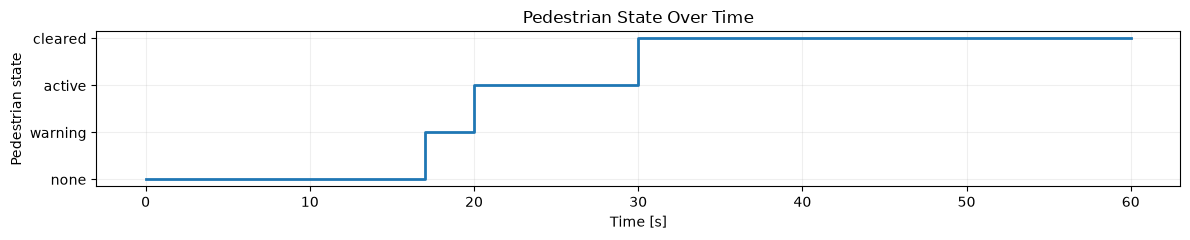

In [7]:
# Cell 7 — Pedestrian timeline

print("===== PEDESTRIAN TIMELINE =====")

for state in ["none", "warning", "active", "cleared"]:
    idx = np.where(pedestrian_state == state)[0]

    if len(idx):
        print(
            f"{state:>8}: "
            f"{time[idx[0]]:.1f} s to {time[idx[-1]]:.1f} s"
        )

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 2.5))

state_numeric = {
    "none": 0,
    "warning": 1,
    "active": 2,
    "cleared": 3,
}

y = np.array([state_numeric[s] for s in pedestrian_state])

ax.step(time, y, where="post", linewidth=2)
ax.set_yticks(list(state_numeric.values()))
ax.set_yticklabels(list(state_numeric.keys()))
ax.set_xlabel("Time [s]")
ax.set_ylabel("Pedestrian state")
ax.set_title("Pedestrian State Over Time")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


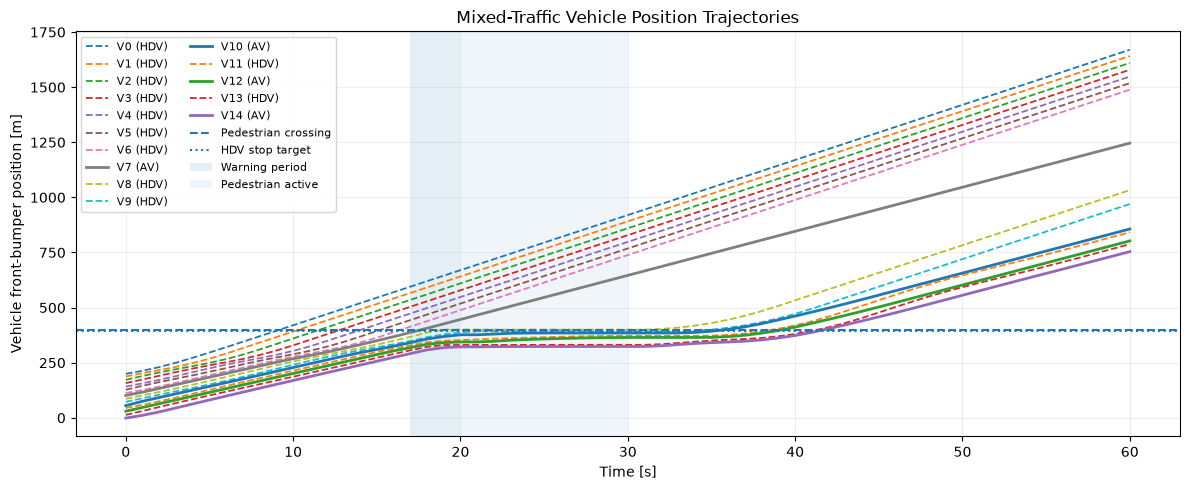

In [8]:
# Cell 8 — Vehicle position trajectories

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

for i in range(positions.shape[1]):

    vehicle_id = int(df.iloc[i]["vehicle_id"])

    if vehicle_types[i] == "AV":
        linestyle = "-"
        linewidth = 2.0
    else:
        linestyle = "--"
        linewidth = 1.3

    ax.plot(
        time,
        positions[:, i],
        linestyle=linestyle,
        linewidth=linewidth,
        label=f"V{vehicle_id} ({vehicle_types[i]})"
    )

ax.axhline(
    PEDESTRIAN_POSITION,
    linestyle="--",
    linewidth=1.5,
    label="Pedestrian crossing"
)

ax.axhline(
    X_STOP,
    linestyle=":",
    linewidth=1.5,
    label="HDV stop target"
)

ax.axvspan(
    T_WARNING_START,
    PEDESTRIAN_TIME,
    alpha=0.12,
    label="Warning period"
)

ax.axvspan(
    PEDESTRIAN_TIME,
    T_PEDESTRIAN_END,
    alpha=0.07,
    label="Pedestrian active"
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Vehicle front-bumper position [m]")
ax.set_title("Mixed-Traffic Vehicle Position Trajectories")

ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

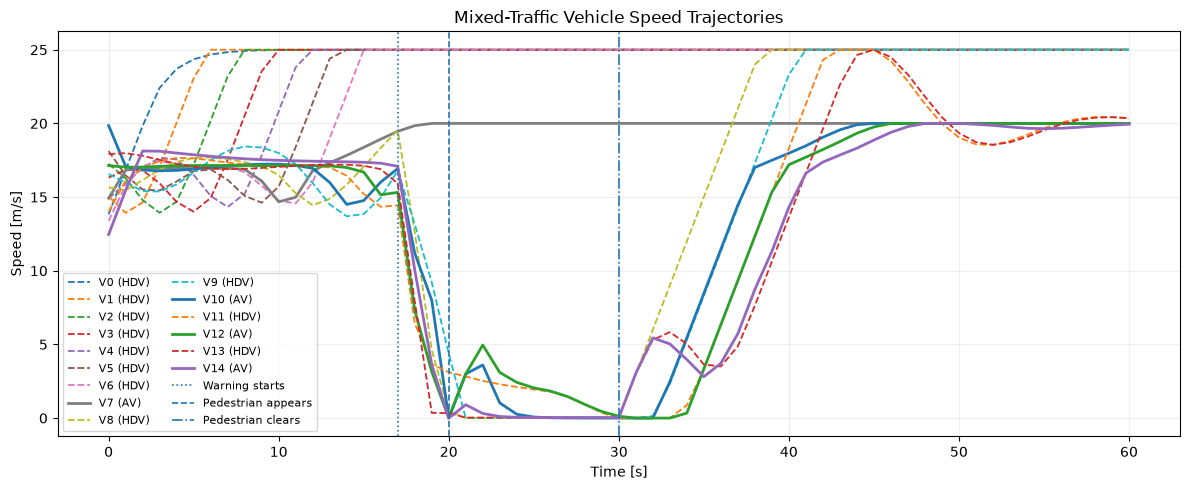

In [9]:
# Cell 9 — Vehicle speed trajectories

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

for i in range(speeds.shape[1]):

    vehicle_id = int(df.iloc[i]["vehicle_id"])

    if vehicle_types[i] == "AV":
        linestyle = "-"
        linewidth = 2.0
    else:
        linestyle = "--"
        linewidth = 1.3

    ax.plot(
        time,
        speeds[:, i],
        linestyle=linestyle,
        linewidth=linewidth,
        label=f"V{vehicle_id} ({vehicle_types[i]})"
    )

ax.axvline(
    T_WARNING_START,
    linestyle=":",
    linewidth=1.2,
    label="Warning starts"
)

ax.axvline(
    PEDESTRIAN_TIME,
    linestyle="--",
    linewidth=1.2,
    label="Pedestrian appears"
)

ax.axvline(
    T_PEDESTRIAN_END,
    linestyle="-.",
    linewidth=1.2,
    label="Pedestrian clears"
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Speed [m/s]")
ax.set_title("Mixed-Traffic Vehicle Speed Trajectories")

ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

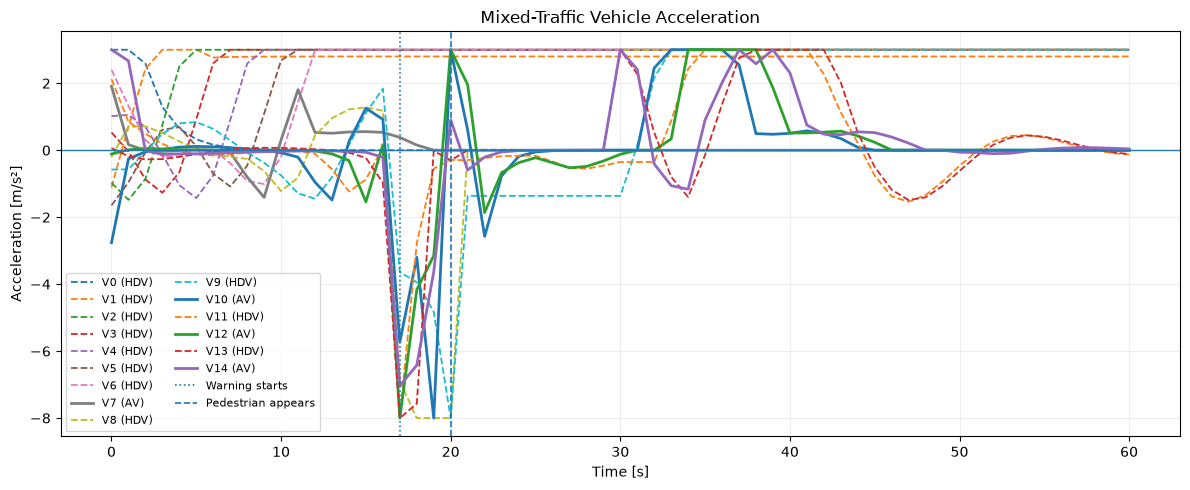

In [10]:
# Cell 10 — Vehicle acceleration trajectories

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

for i in range(accelerations.shape[1]):

    vehicle_id = int(df.iloc[i]["vehicle_id"])

    if vehicle_types[i] == "AV":
        linestyle = "-"
        linewidth = 2.0
    else:
        linestyle = "--"
        linewidth = 1.3

    ax.plot(
        time,
        accelerations[:, i],
        linestyle=linestyle,
        linewidth=linewidth,
        label=f"V{vehicle_id} ({vehicle_types[i]})"
    )

ax.axhline(0.0, linewidth=1.0)

ax.axvline(
    T_WARNING_START,
    linestyle=":",
    linewidth=1.2,
    label="Warning starts"
)

ax.axvline(
    PEDESTRIAN_TIME,
    linestyle="--",
    linewidth=1.2,
    label="Pedestrian appears"
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Acceleration [m/s²]")
ax.set_title("Mixed-Traffic Vehicle Acceleration")

ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

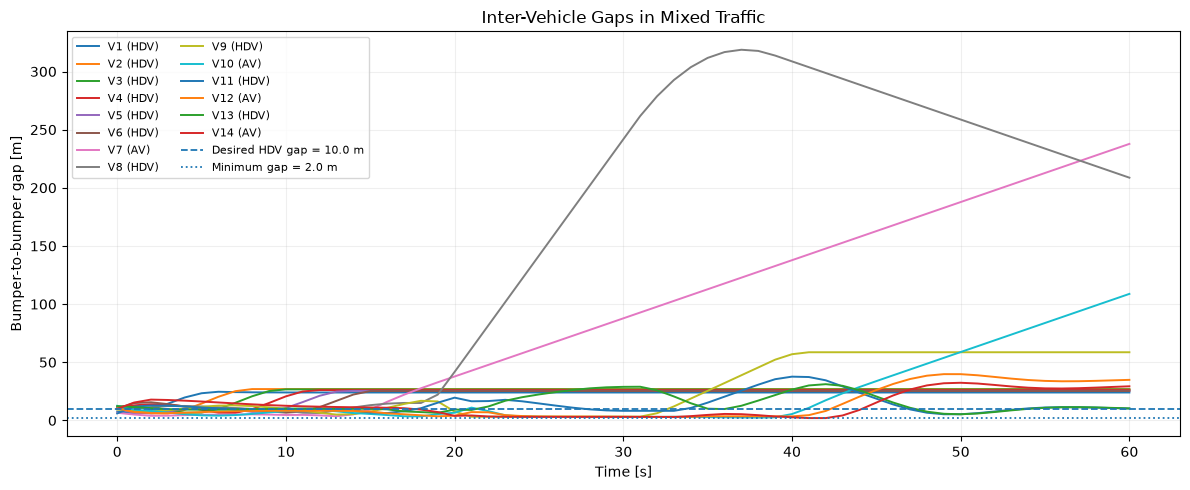

In [11]:
# Cell 11 — Inter-vehicle gaps

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

for i in range(1, gaps.shape[1]):

    vehicle_id = int(df.iloc[i]["vehicle_id"])

    ax.plot(
        time,
        gaps[:, i],
        linewidth=1.4,
        label=f"V{vehicle_id} ({vehicle_types[i]})"
    )

ax.axhline(
    DESIRED_GAP,
    linestyle="--",
    linewidth=1.3,
    label=f"Desired HDV gap = {DESIRED_GAP:.1f} m"
)

ax.axhline(
    MIN_GAP,
    linestyle=":",
    linewidth=1.3,
    label=f"Minimum gap = {MIN_GAP:.1f} m"
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Bumper-to-bumper gap [m]")
ax.set_title("Inter-Vehicle Gaps in Mixed Traffic")

ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

In [12]:
# Cell 12 — HDV pedestrian response

print("===== HDV PEDESTRIAN RESPONSE =====")

response_rows = []

for i in range(positions.shape[1]):

    vehicle_id = int(df.iloc[i]["vehicle_id"])

    # AVs do not use the HDV pedestrian acceleration model
    if vehicle_types[i] == "AV":
        continue

    mask = np.isfinite(
        pedestrian_accelerations[:, i]
    )

    if np.any(mask):

        idx = np.where(mask)[0]

        response_rows.append({
            "vehicle_id": vehicle_id,
            "type": "HDV",
            "first_response_s": time[idx[0]],
            "last_response_s": time[idx[-1]],
            "position_at_first_response_m": positions[idx[0], i],
            "speed_at_first_response_mps": speeds[idx[0], i],
            "minimum_pedestrian_accel_mps2": np.min(
                pedestrian_accelerations[idx, i]
            ),
        })

    else:

        response_rows.append({
            "vehicle_id": vehicle_id,
            "type": "HDV",
            "first_response_s": np.nan,
            "last_response_s": np.nan,
            "position_at_first_response_m": np.nan,
            "speed_at_first_response_mps": np.nan,
            "minimum_pedestrian_accel_mps2": np.nan,
        })

response_df = pd.DataFrame(response_rows)

display(response_df)

===== HDV PEDESTRIAN RESPONSE =====


,vehicle_id,type,first_response_s,last_response_s,position_at_first_response_m,speed_at_first_response_mps,minimum_pedestrian_accel_mps2
0,0,HDV,NaN,NaN,NaN,NaN,NaN
1,1,HDV,NaN,NaN,NaN,NaN,NaN
2,2,HDV,NaN,NaN,NaN,NaN,NaN
3,3,HDV,NaN,NaN,NaN,NaN,NaN
4,4,HDV,NaN,NaN,NaN,NaN,NaN
5,5,HDV,NaN,NaN,NaN,NaN,NaN
6,6,HDV,NaN,NaN,NaN,NaN,NaN
7,8,HDV,17.0,29.0,367.377609,19.518755,-8.0
8,9,HDV,17.0,29.0,348.748633,16.800872,-8.0
9,11,HDV,17.0,29.0,328.205750,14.438807,-8.0


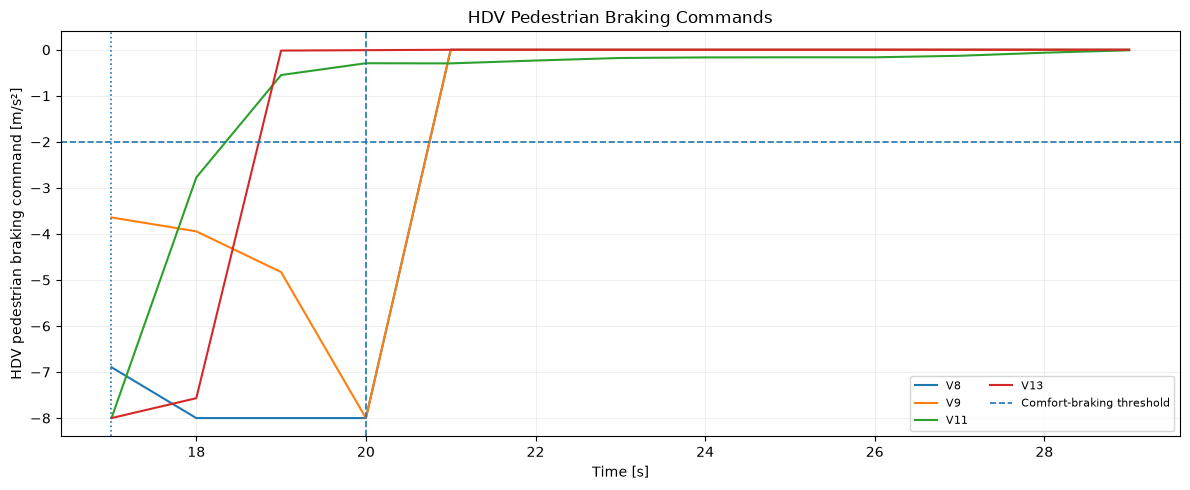

In [13]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

for i in range(positions.shape[1]):

    if vehicle_types[i] != "HDV":
        continue

    mask = np.isfinite(
        pedestrian_accelerations[:, i]
    )

    if np.any(mask):

        vehicle_id = int(df.iloc[i]["vehicle_id"])

        ax.plot(
            time[mask],
            pedestrian_accelerations[mask, i],
            linewidth=1.5,
            label=f"V{vehicle_id}"
        )

ax.axhline(
    -PEDESTRIAN_HDV_COMFORT_BRAKE,
    linestyle="--",
    linewidth=1.2,
    label="Comfort-braking threshold"
)

ax.axvline(
    T_WARNING_START,
    linestyle=":",
    linewidth=1.2
)

ax.axvline(
    PEDESTRIAN_TIME,
    linestyle="--",
    linewidth=1.2
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("HDV pedestrian braking command [m/s²]")
ax.set_title("HDV Pedestrian Braking Commands")

ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

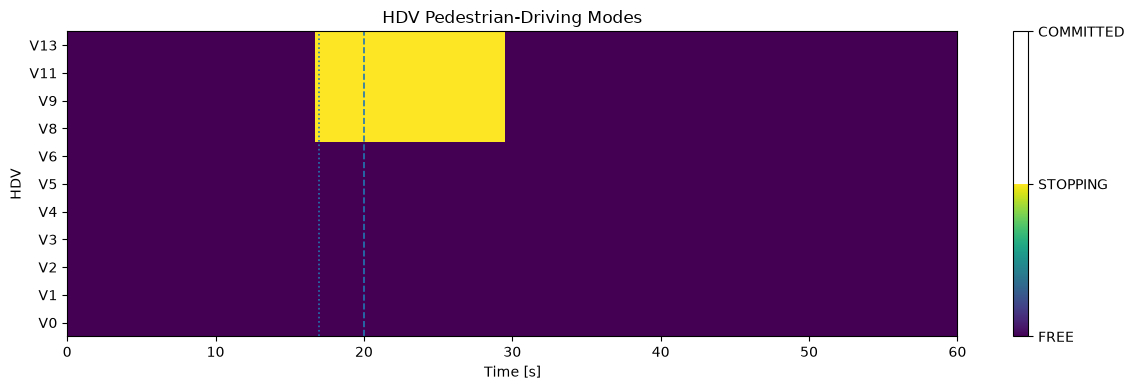

In [14]:
# Cell 13A — HDV pedestrian-driving modes

hdv_indices = np.where(vehicle_types == "HDV")[0]

if len(hdv_indices) > 0:

    hdv_modes = modes[:, hdv_indices]

    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4))

    image = ax.imshow(
        hdv_modes.T,
        aspect="auto",
        origin="lower",
        extent=[
            time[0],
            time[-1],
            -0.5,
            len(hdv_indices) - 0.5
        ],
        interpolation="nearest"
    )

    cbar = fig.colorbar(image, ax=ax)

    cbar.set_ticks([
        MODE_FREE,
        MODE_STOPPING,
        MODE_COMMITTED
    ])

    cbar.set_ticklabels([
        "FREE",
        "STOPPING",
        "COMMITTED"
    ])

    ax.axvline(
        T_WARNING_START,
        linestyle=":",
        linewidth=1.2
    )

    ax.axvline(
        PEDESTRIAN_TIME,
        linestyle="--",
        linewidth=1.2
    )

    ax.set_yticks(np.arange(len(hdv_indices)))

    ax.set_yticklabels([
        f"V{int(df.iloc[i]['vehicle_id'])}"
        for i in hdv_indices
    ])

    ax.set_xlabel("Time [s]")
    ax.set_ylabel("HDV")
    ax.set_title("HDV Pedestrian-Driving Modes")

    plt.tight_layout()
    plt.show()

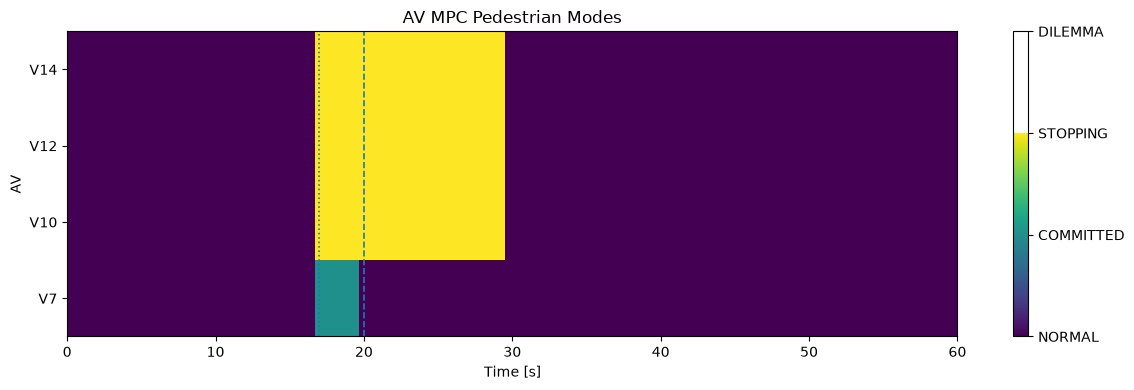

In [15]:
# Cell 13B — AV MPC pedestrian modes

av_indices = np.where(vehicle_types == "AV")[0]

av_mode_names = {
    "normal": 0,
    "committed": 1,
    "stopping": 2,
    "dilemma": 3,
}

av_mode_history = np.full(
    (len(time), len(av_indices)),
    np.nan
)

for k in range(len(time)):

    for j, vehicle_index in enumerate(av_indices):

        diagnostics = mpc_diagnostics[k][vehicle_index]

        if diagnostics is None:
            continue

        mode = diagnostics.get(
            "pedestrian_mode",
            "normal"
        )

        av_mode_history[k, j] = av_mode_names.get(
            mode,
            np.nan
        )

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4))

image = ax.imshow(
    av_mode_history.T,
    aspect="auto",
    origin="lower",
    extent=[
        time[0],
        time[-1],
        -0.5,
        len(av_indices) - 0.5
    ],
    interpolation="nearest"
)

cbar = fig.colorbar(image, ax=ax)

cbar.set_ticks([
    0,
    1,
    2,
    3
])

cbar.set_ticklabels([
    "NORMAL",
    "COMMITTED",
    "STOPPING",
    "DILEMMA"
])

ax.axvline(
    T_WARNING_START,
    linestyle=":",
    linewidth=1.2
)

ax.axvline(
    PEDESTRIAN_TIME,
    linestyle="--",
    linewidth=1.2
)

ax.set_yticks(np.arange(len(av_indices)))

ax.set_yticklabels([
    f"V{int(df.iloc[i]['vehicle_id'])}"
    for i in av_indices
])

ax.set_xlabel("Time [s]")
ax.set_ylabel("AV")
ax.set_title("AV MPC Pedestrian Modes")

plt.tight_layout()
plt.show()

In [16]:
# Cell 13C — AV clearance diagnostics

print("===== AV CLEARANCE DIAGNOSTICS =====")

for vehicle_index in av_indices:

    vehicle_id = int(
        df.iloc[vehicle_index]["vehicle_id"]
    )

    predicted_positions = []
    clearance_possible = []
    modes_for_vehicle = []

    for k in range(len(time)):

        diagnostics = mpc_diagnostics[k][vehicle_index]

        if diagnostics is None:
            continue

        predicted_position = diagnostics.get(
            "predicted_position_at_pedestrian_time"
        )

        # Only store actual numeric predictions.
        if predicted_position is not None:
            predicted_positions.append(
                float(predicted_position)
            )

        clearance_possible_value = diagnostics.get(
            "pedestrian_clearance_possible"
        )

        if clearance_possible_value is not None:
            clearance_possible.append(
                bool(clearance_possible_value)
            )

        modes_for_vehicle.append(
            diagnostics.get(
                "pedestrian_mode",
                "normal"
            )
        )

    print(f"\nVehicle {vehicle_id} (AV)")

    # ---------------------------------------------------------
    # Predicted position at pedestrian arrival
    # ---------------------------------------------------------

    if predicted_positions:

        max_predicted_position = max(
            predicted_positions
        )

        required_clearance_position = (
            PEDESTRIAN_POSITION + VEHICLE_LENGTH
        )

        print(
            "  Maximum predicted position at "
            f"pedestrian time: {max_predicted_position:.2f} m"
        )

        print(
            "  Required clearance position: "
            f"{required_clearance_position:.2f} m"
        )

    else:

        print(
            "  No predicted position at pedestrian "
            "arrival was recorded."
        )

    # ---------------------------------------------------------
    # Clearance decisions
    # ---------------------------------------------------------

    if clearance_possible:

        print(
            "  Clearance possible decisions: "
            f"{sum(clearance_possible)} true / "
            f"{len(clearance_possible)} evaluated"
        )

    else:

        print(
            "  No clearance decision was recorded."
        )

    # ---------------------------------------------------------
    # MPC pedestrian modes
    # ---------------------------------------------------------

    print(
        "  Modes observed: "
        f"{sorted(set(modes_for_vehicle))}"
    )

===== AV CLEARANCE DIAGNOSTICS =====

Vehicle 7 (AV)
  Maximum predicted position at pedestrian time: 446.20 m
  Required clearance position: 404.50 m
  Clearance possible decisions: 3 true / 3 evaluated
  Modes observed: ['committed', 'normal']

Vehicle 10 (AV)
  Maximum predicted position at pedestrian time: 381.73 m
  Required clearance position: 404.50 m
  Clearance possible decisions: 0 true / 3 evaluated
  Modes observed: ['normal', 'stopping']

Vehicle 12 (AV)
  Maximum predicted position at pedestrian time: 344.22 m
  Required clearance position: 404.50 m
  Clearance possible decisions: 0 true / 3 evaluated
  Modes observed: ['normal', 'stopping']

Vehicle 14 (AV)
  Maximum predicted position at pedestrian time: 323.52 m
  Required clearance position: 404.50 m
  Clearance possible decisions: 0 true / 3 evaluated
  Modes observed: ['normal', 'stopping']


In [17]:
# Cell 14 — HDV pedestrian infeasible events

print("===== HDV PEDESTRIAN INFEASIBLE EVENTS =====")

if len(infeasible_events) == 0:
    print("No infeasible events were recorded.")
else:
    event_rows = []

    for event_time, vehicle_index, position, speed in infeasible_events:
        event_rows.append({
            "time_s": event_time,
            "vehicle_index": vehicle_index,
            "vehicle_id": int(df.iloc[vehicle_index]["vehicle_id"]),
            "position_m": position,
            "speed_mps": speed,
        })

    infeasible_df = pd.DataFrame(event_rows)

    print(f"Total recorded infeasible events: {len(infeasible_df)}")
    display(infeasible_df)

    print("Events by vehicle:")
    display(
        infeasible_df.groupby("vehicle_id")
        .agg(
            number_of_events=("time_s", "size"),
            first_event_s=("time_s", "min"),
            last_event_s=("time_s", "max"),
            first_position_m=("position_m", "first"),
            first_speed_mps=("speed_mps", "first"),
        )
        .reset_index()
    )

    # Event timing by vehicle
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4))

    for vehicle_id, group in infeasible_df.groupby("vehicle_id"):
        ax.scatter(
            group["time_s"],
            np.full(len(group), vehicle_id),
            marker="x",
            s=45
        )

    ax.axvline(T_WARNING_START, linestyle=":", linewidth=1.2,
               label="Warning starts")
    ax.axvline(PEDESTRIAN_TIME, linestyle="--", linewidth=1.2,
               label="Pedestrian appears")

    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Vehicle ID")
    ax.set_title("Recorded Infeasible Events")
    ax.grid(alpha=0.2)
    ax.legend()

    plt.tight_layout()
    plt.show()


===== HDV PEDESTRIAN INFEASIBLE EVENTS =====
No infeasible events were recorded.


In [18]:
# Cell 15 — Infeasible events on the position trajectories

if len(infeasible_events) == 0:
    print("No infeasible events to overlay.")
else:
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))

    for i in range(positions.shape[1]):
        vehicle_id = int(df.iloc[i]["vehicle_id"])
        ax.plot(time, positions[:, i], linewidth=1.2)

    for event_time, vehicle_index, position, speed in infeasible_events:
        vehicle_id = int(df.iloc[vehicle_index]["vehicle_id"])
        ax.scatter(
            event_time,
            position,
            marker="x",
            s=55
        )
        ax.annotate(
            f"V{vehicle_id}",
            (event_time, position),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8
        )

    ax.axhline(PEDESTRIAN_POSITION, linestyle="--", linewidth=1.5,
               label="Pedestrian crossing")
    ax.axhline(X_STOP, linestyle=":", linewidth=1.5,
               label="HDV stop target")

    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Vehicle front-bumper position [m]")
    ax.set_title("HDV Pedestrian Infeasible Events Along Vehicle Trajectories")
    ax.grid(alpha=0.2)
    ax.legend()

    plt.tight_layout()
    plt.show()


No infeasible events to overlay.


In [19]:
# Cell 16 — Mixed-traffic summary per vehicle

summary_rows = []

for i in range(positions.shape[1]):

    vehicle_id = int(df.iloc[i]["vehicle_id"])
    vehicle_type = vehicle_types[i]

    vehicle_gaps = gaps[:, i]
    valid_gaps = vehicle_gaps[np.isfinite(vehicle_gaps)]

    vehicle_events = [
        e for e in infeasible_events
        if e[1] == i
    ]

    row = {
        "vehicle_id": vehicle_id,
        "type": vehicle_type,
        "initial_position_m": positions[0, i],
        "initial_speed_mps": speeds[0, i],
        "final_position_m": positions[-1, i],
        "final_speed_mps": speeds[-1, i],
        "minimum_gap_m": (
            np.min(valid_gaps)
            if len(valid_gaps)
            else np.nan
        ),
        "infeasible_event_count": len(vehicle_events),
        "wall_hit_count": int(
            np.sum(wall_hits[:, i])
        ),
    }

    # ---------------------------------------------------------
    # HDV-specific information
    # ---------------------------------------------------------

    if vehicle_type == "HDV":

        response_mask = np.isfinite(
            pedestrian_accelerations[:, i]
        )

        row["first_pedestrian_response_s"] = (
            time[np.where(response_mask)[0][0]]
            if np.any(response_mask)
            else np.nan
        )

        row["minimum_pedestrian_accel_mps2"] = (
            np.min(
                pedestrian_accelerations[
                    response_mask, i
                ]
            )
            if np.any(response_mask)
            else np.nan
        )

        row["mpc_success_rate"] = np.nan
        row["final_pedestrian_mode"] = (
            MODE_NAMES[modes[-1, i]]
        )

    # ---------------------------------------------------------
    # AV-specific information
    # ---------------------------------------------------------

    else:

        av_success = []
        av_modes = []

        for k in range(len(time)):

            diagnostics = mpc_diagnostics[k][i]

            if diagnostics is None:
                continue

            av_success.append(
                diagnostics["success"]
            )

            av_modes.append(
                diagnostics.get(
                    "pedestrian_mode",
                    "normal"
                )
            )

        row["first_pedestrian_response_s"] = np.nan
        row["minimum_pedestrian_accel_mps2"] = np.nan

        row["mpc_success_rate"] = (
            100 * np.mean(av_success)
            if av_success
            else np.nan
        )

        row["final_pedestrian_mode"] = (
            av_modes[-1]
            if av_modes
            else None
        )

    summary_rows.append(row)

vehicle_summary = pd.DataFrame(summary_rows)

display(vehicle_summary)

,vehicle_id,type,initial_position_m,initial_speed_mps,final_position_m,final_speed_mps,minimum_gap_m,infeasible_event_count,wall_hit_count,first_pedestrian_response_s,minimum_pedestrian_accel_mps2,mpc_success_rate,final_pedestrian_mode
0,0,HDV,199.50,13.83,1669.820000,25.000000,NaN,0,0,NaN,NaN,NaN,FREE
1,1,HDV,187.52,15.04,1641.323650,25.000000,6.270000,0,0,NaN,NaN,NaN,FREE
2,2,HDV,172.36,17.25,1609.884050,25.000000,5.944500,0,0,NaN,NaN,NaN,FREE
3,3,HDV,157.54,16.32,1578.685852,25.000000,6.654950,0,0,NaN,NaN,NaN,FREE
4,4,HDV,141.48,14.91,1548.112928,25.000000,6.462471,0,0,NaN,NaN,NaN,FREE
5,5,HDV,127.20,18.12,1518.219864,25.000000,6.026000,0,0,NaN,NaN,NaN,FREE
6,6,HDV,112.52,13.39,1488.461630,25.000000,6.668467,0,0,NaN,NaN,NaN,FREE
7,7,AV,101.46,14.92,1246.200272,20.000000,3.553266,0,0,NaN,NaN,100.0,normal
8,8,HDV,86.12,15.66,1032.990000,25.000000,6.323762,0,2,17.0,-8.0,NaN,FREE
9,9,HDV,72.26,16.56,969.880240,25.000000,3.181400,0,0,17.0,-8.0,NaN,FREE


In [20]:
# Cell 17 — AV-specific summary

av_summary = vehicle_summary[
    vehicle_summary["type"] == "AV"
].copy()

print("===== AV SUMMARY =====")

display(
    av_summary[
        [
            "vehicle_id",
            "initial_position_m",
            "initial_speed_mps",
            "final_position_m",
            "final_speed_mps",
            "minimum_gap_m",
            "mpc_success_rate",
            "final_pedestrian_mode",
        ]
    ]
)

===== AV SUMMARY =====


,vehicle_id,initial_position_m,initial_speed_mps,final_position_m,final_speed_mps,minimum_gap_m,mpc_success_rate,final_pedestrian_mode
7,7,101.46,14.92,1246.200272,20.000000,3.553266,100.0,normal
10,10,55.23,19.85,856.590071,20.000000,2.375067,100.0,normal
12,12,29.90,17.14,802.531125,20.000000,3.044942,100.0,normal
14,14,-1.27,12.46,753.879806,19.943999,2.000000,100.0,normal


In [21]:
# Cell 18 — Animate the complete 60 s mixed-traffic simulation
# View region: 200 m to 600 m

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle
from IPython.display import HTML, display

# ------------------------------------------------------------
# Animation settings
# ------------------------------------------------------------

X_MIN = 300.0
X_MAX = 500.0

FIG_WIDTH = 16
FIG_HEIGHT = 5

VEHICLE_HEIGHT = 0.09
ROAD_Y = 0.0
ROAD_HEIGHT = 0.2 + VEHICLE_HEIGHT

#VEHICLE_HEIGHT = 0.5
#ROAD_Y = 0.0
#ROAD_HEIGHT = VEHICLE_HEIGHT + 0.25

LABEL_Y_OFFSET = 0.25

# Acceleration threshold for label colour
ACCEL_THRESHOLD = 0.05


# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(FIG_WIDTH, FIG_HEIGHT)
)

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(-1.0, ROAD_HEIGHT + 2.0)

ax.set_xlabel("Longitudinal position [m]")
ax.set_ylabel("Road")
ax.set_title("Mixed Traffic Simulation")

ax.set_yticks([])

# Road
road = Rectangle(
    (X_MIN, -ROAD_HEIGHT / 2),
    X_MAX - X_MIN,
    ROAD_HEIGHT,
    facecolor="lightgray",
    edgecolor="black"
)



ax.add_patch(road)


# ------------------------------------------------------------
# Pedestrian crossing
# ------------------------------------------------------------

pedestrian_x = PEDESTRIAN_POSITION

pedestrian_line = ax.axvline(
    pedestrian_x,
    linestyle="--",
    linewidth=2,
    color="black"
)

ax.text(
    pedestrian_x,
    ROAD_HEIGHT + 1.0,
    "Pedestrian crossing",
    ha="center",
    va="bottom"
)


# HDV stopping position
stop_x = PEDESTRIAN_POSITION - PEDESTRIAN_HDV_SAFE_DISTANCE

stop_line = ax.axvline(
    stop_x,
    linestyle=":",
    linewidth=1.5,
    color="black"
)

ax.text(
    stop_x,
    ROAD_HEIGHT + 0.45,
    "HDV stop",
    ha="center",
    va="bottom"
)


# ------------------------------------------------------------
# Vehicle graphics
# ------------------------------------------------------------

vehicle_patches = []
vehicle_labels = []

for i in range(len(df)):

    vehicle_type = str(
        df.iloc[i]["type"]
    ).upper()

    if vehicle_type == "AV":
        vehicle_color = "red"
    else:
        vehicle_color = "steelblue"

    # Vehicle rectangle
    vehicle = Rectangle(
        (
            positions[0][i] - VEHICLE_LENGTH,
            ROAD_Y - VEHICLE_HEIGHT / 2
        ),
        VEHICLE_LENGTH,
        VEHICLE_HEIGHT,
        facecolor=vehicle_color,
        edgecolor="black",
        linewidth=1.0
    )

    
    ax.add_patch(vehicle)
    vehicle_patches.append(vehicle)

    # Vehicle label
    label = ax.text(
        positions[0][i] - VEHICLE_LENGTH / 2,
        ROAD_Y + VEHICLE_HEIGHT + LABEL_Y_OFFSET,
        str(int(df.iloc[i]["vehicle_id"])),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="black"
    )

    vehicle_labels.append(label)


# ------------------------------------------------------------
# Time / pedestrian information
# ------------------------------------------------------------

time_text = ax.text(
    0.02,
    0.92,
    "",
    transform=ax.transAxes,
    fontsize=11,
    fontweight="bold"
)

pedestrian_text = ax.text(
    0.98,
    0.92,
    "",
    transform=ax.transAxes,
    fontsize=11,
    fontweight="bold",
    ha="right"
)


# ------------------------------------------------------------
# Animation update function
# ------------------------------------------------------------

def update(frame):

    current_time = time[frame]

    # --------------------------------------------------------
    # Update each vehicle
    # --------------------------------------------------------

    for i in range(len(df)):

        x = positions[frame][i]

        # Rectangle position
        vehicle_patches[i].set_x(
            x - VEHICLE_LENGTH
        )

        # ----------------------------------------------------
        # Vehicle label position
        # ----------------------------------------------------

        vehicle_labels[i].set_x(
            x - VEHICLE_LENGTH / 2
        )

        # ----------------------------------------------------
        # Label colour based on acceleration
        # ----------------------------------------------------

        acceleration = accelerations[frame][i]

        if acceleration > ACCEL_THRESHOLD:

            # Accelerating
            label_color = "green"

        elif acceleration < -ACCEL_THRESHOLD:

            # Braking
            label_color = "red"

        else:

            # Approximately constant speed
            label_color = "black"

        vehicle_labels[i].set_color(
            label_color
        )

    # --------------------------------------------------------
    # Simulation time
    # --------------------------------------------------------

    time_text.set_text(
        f"Time: {current_time:.1f} s"
    )

    # --------------------------------------------------------
    # Pedestrian state
    # --------------------------------------------------------

    state = pedestrian_state[frame]

    pedestrian_text.set_text(
        f"Pedestrian: {str(state).upper()}"
    )

    return (
        vehicle_patches
        + vehicle_labels
        + [time_text, pedestrian_text]
    )


# ------------------------------------------------------------
# Create animation
# ------------------------------------------------------------

animation = FuncAnimation(
    fig,
    update,
    frames=len(time),
    interval=DT * 1000,
    blit=True,
    repeat=False
)

plt.close(fig)

display(
    HTML(
        animation.to_jshtml()
    )
)